# Lorenz Equations
    <Joseph wilkes>
    <Class: m437>
    <Oct 8th, 2020>

# Notes from class


In [ ]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.animation import FuncAnimation as FuncAnimation
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import linregress
plt.rcParams['animation.ffmpeg_path'] = '/Users/joeywilkes/Desktop/ffmpeg'
from IPython import display #one way of visualizing it

In [ ]:
# %matplotlib notebook
%matplotlib inline

## Problem 1
Write a function that implements the Lorenz equations. Let $\sigma = 10$, $\rho = 28$, $\beta = 8$ . Make a 3D plot of a solution to the Lorenz equations for an initial condition where $(x, y, z)$ are drawn randomly from a uniform distribution from −15 to 15. As usual, use `scipy .integrate.odeint` to compute the solution.

In [ ]:
def lorenz(x,t):
    """Implements Lorenz equations:

    dx/dt = σ(y − x)
    dy/dt = ρx − y − xz
    dz/dt = xy − βz

    Parameters:
        x ((3,) ndarray): The state values (x,y,z)
        t (float): The time value t
    Returns:
        ((3,) ndarray): The derivative values
    """
    # s for sigma, p for rho (cuz it looks like a p), b for beta
    s,p,b = 10,28,8/3
    #s,p,b = 10,28,1
    return np.array([
        s * (x[1] - x[0])
        , p * x[0] - x[1] - x[0] * x[2]
        , x[0] * x[1] - b * x[2]
    ])

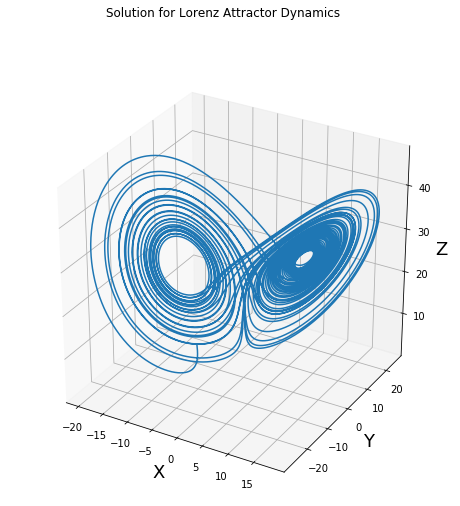

In [ ]:
y0 = np.random.uniform(-15,15,size=3)
# print(y0)
t_final = 50
domain = np.linspace(0,t_final,int(5e4))
y = odeint(lorenz,y0,domain)

# Create figure object.
fig = plt.figure(figsize=(8,8))

# Create 3D axis object using add_subplot().
ax = fig.add_subplot(111, projection='3d')
ax.plot(y[:,0],y[:,1],y[:,2])
fig.suptitle('Solution for Lorenz Attractor Dynamics')
ax.set_xlabel('X',fontsize=18)
ax.set_ylabel('Y',fontsize=18)
ax.set_zlabel('Z',fontsize=18)
plt.show()

## Problem 2
To better visualize the Lorenz attractor, produce a single 3D plot displaying three solutions to the Lorenz equations, each with random initial conditions.

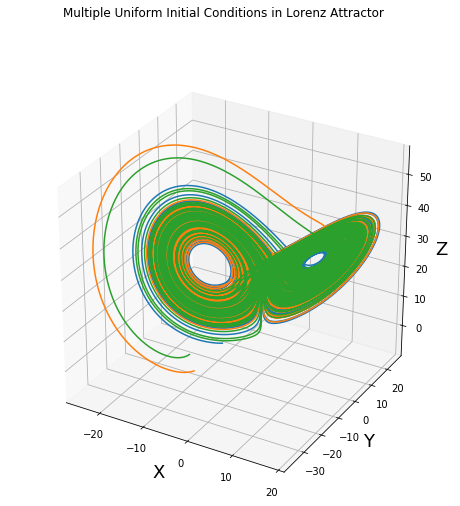

In [ ]:
# Create figure object.

"really interesting behavior when beta = 4, numsamples = 5, and t_final = 5"

fig = plt.figure(figsize=(8,8))

# Create 3D axis object using add_subplot().
ax = fig.add_subplot(111, projection='3d')

uniform_boundary = 15

num_samples = 3
for i in range(num_samples):
    y0 = np.random.uniform(-uniform_boundary,uniform_boundary,size=3)
    # print(y0)
    t_final = 100
    domain = np.linspace(0,t_final,int(5e4))
    y = odeint(lorenz,y0,domain)
    #ax.plot(y[:,0],y[:,1],y[:,2],color='blue')
    ax.plot(y[:,0],y[:,1],y[:,2])
fig.suptitle('Multiple Uniform Initial Conditions in Lorenz Attractor')
ax.set_xlabel('X',fontsize=18)
ax.set_ylabel('Y',fontsize=18)
ax.set_zlabel('Z',fontsize=18)
plt.show()

## Problem 3
Use `matplotlib.animation.FuncAnimation` to produce a 3D animation of two solutions to the Lorenz equations with similar initial conditions. To make similar initial conditions, draw $(x_1,y_1,z_1)$ randomly as before, and then produce $(x_2,y_2,z_2)$ by adding a small perturbation: `np.random.randn(3)*(1e-10)`. It will take several seconds before the separation between the two solutions will be noticeable.

The animation should have a point marker and the past trajectory curve for each solution. Save your animation as `lorenz_animation1.mp4`.

(Recall that you can display the saved animation in a Jupyter notebook by running the follwing code in a markdown cell):

`<video src='lorenz_animation1.mp4' controls>`

In [ ]:
animation.writer = animation.writers['ffmpeg']

uniform_boundary = 15
y0 = np.random.uniform(-uniform_boundary,uniform_boundary,size=3)
y1 = y0 + np.random.random((3,)) / int(1e8)
t_final = 500
domain = np.linspace(0,t_final,int(5e4))
sol_0 = odeint(lorenz,y0,domain)
sol_1 = odeint(lorenz,y1,domain)

# Create figure object.
fig = plt.figure(figsize=(8,8))

# Create 3D axis object using add_subplot().
ax = fig.add_subplot(111, projection='3d')

ALPHA=0.70

part1, = plt.plot([],[],[],marker='o',color='blue',alpha=ALPHA,markersize=15)
traj1, = plt.plot([],[],[],linestyle='-',alpha=ALPHA,label='original',color='blue')
part2, = plt.plot([],[],[],marker='o',color='red',markersize=15)
traj2, = plt.plot([],[],[],linestyle='-',alpha=ALPHA,label='perturbation',color='red')

ax.set_xlim3d(-30,30)
ax.set_ylim3d(-50,50)
ax.set_zlim3d(-20,60)

def update(i):
    # plot the position in 3d space of the position of the first particle
    part1.set_data(sol_0[i][0],sol_0[i][1])
    part1.set_3d_properties(sol_0[i][2])
    # plot the position in 3d space of the position of the second particle
    part2.set_data(sol_1[i][0],sol_1[i][1])
    part2.set_3d_properties(sol_1[i][2])
    # plot the position in 3d space of the trajectory of the first particle
    traj1.set_data(sol_0[:i,0],sol_0[:i,1])
    traj1.set_3d_properties(sol_0[:i,2])
    # plot the position in 3d space of the trajectory of the second particle
    traj2.set_data(sol_1[:i,0],sol_1[:i,1])
    traj2.set_3d_properties(sol_1[:i,2])

    return part1, part2, traj1, traj2

ani = FuncAnimation(fig, update, frames=range(5000), interval=15)
fig.suptitle('Divergence of Pertubed solutions in Lorenz Attractor')
plt.legend(loc='best')
ax.set_xlabel('X',fontsize=18)
ax.set_ylabel('Y',fontsize=18)
ax.set_zlabel('Z',fontsize=18)

ani.save("lorenz_animation3.mp4")
plt.close()

#
lorenz_animation3 is better than lorenz_animation1

In [ ]:
# <video src="lorenz_animation1.mp4" controls>

<video src="lorenz_animation3.mp4" controls>

## Problem 4
The `odeint` function allows users to specify error tolerances (similar to setting a value of $h$ for a Runge-Kutta method). Using a single random initial condition, produce two approximations by using the odeint arguments `(atol=1e-15, rtol=1e-13)` for the first approximation and `(atol=1e-12, rtol=1e-10)` for the second.
As in the previous problem, use `FuncAnimation` to animate both solutions. Save the animation as `lorenz_animation2.mp4`.

In [ ]:
animation.writer = animation.writers['ffmpeg']

uniform_boundary = 15
y0 = np.random.uniform(-uniform_boundary,uniform_boundary,size=3)
# print(y0)
t_final = 500
domain = np.linspace(0,t_final,int(5e4))
# perturb the solutions according to the tolerance in the solver
sol_0 = odeint(lorenz,y0,domain,atol=1e-15,rtol=1e-13)
sol_1 = odeint(lorenz,y0,domain,atol=1e-12,rtol=1e-10)

# Create figure object.
fig = plt.figure(figsize=(8,8))

# Create 3D axis object using add_subplot().
ax = fig.add_subplot(111, projection='3d')

ALPHA=0.65

part1, = plt.plot([],[],[],marker='o',color='blue',alpha=ALPHA,markersize=15)
traj1, = plt.plot([],[],[],linestyle='-',alpha=ALPHA,label='original',color='blue')
part2, = plt.plot([],[],[],marker='o',color='red',markersize=15)
traj2, = plt.plot([],[],[],linestyle='-',alpha=ALPHA,label='perturbation',color='red')


ax.set_xlim3d(-30,30)
ax.set_ylim3d(-50,50)
ax.set_zlim3d(-20,60)


def update(i):
    # plot the position in 3d space of the position of the first particle
    part1.set_data(sol_0[i][0],sol_0[i][1])
    part1.set_3d_properties(sol_0[i][2])
    # plot the position in 3d space of the position of the second particle
    part2.set_data(sol_1[i][0],sol_1[i][1])
    part2.set_3d_properties(sol_1[i][2])
    # plot the position in 3d space of the trajectory of the first particle
    traj1.set_data(sol_0[:i,0],sol_0[:i,1])
    traj1.set_3d_properties(sol_0[:i,2])
    # plot the position in 3d space of the trajectory of the second particle
    traj2.set_data(sol_1[:i,0],sol_1[:i,1])
    traj2.set_3d_properties(sol_1[:i,2])

    return part1, part2, traj1, traj2

ani = FuncAnimation(fig, update, frames=range(5000), interval=15)
fig.suptitle('Divergence of Pertubed solutions in Lorenz Attractor')
plt.legend(loc='best')
ax.set_xlabel('X',fontsize=18)
ax.set_ylabel('Y',fontsize=18)
ax.set_zlabel('Z',fontsize=18)

ani.save("lorenz_animation4.mp4")
plt.close()

#
lorenz_animation4 is better than lorenz_animation2

In [ ]:
# <video src="lorenz_animation2.mp4" controls>

<video src="lorenz_animation4.mp4" controls>

## Problem 5
Estimate the Lyapunov exponent of the Lorenz equations by doing the following:
* Produce an initial condition that already lies on the attractor. This can be done by using a random "dummy" initial condition, approximating the resulting solution to the Lorenz system for a short time, and then using the endpoint of that solution (which is now on the attractor) as the desired intital condition.
* Produce a second initial condition by adding a small perturbation to the first (as before).
* For both initial conditions, use `odeint` to produce approximate solutions for $0 \leq t \leq 10$.
* Compute $||\delta(t)||$ by taking the norm of the vector difference between the two solutions for each value of $t$.
* Use `scipy.stats.linregress` to calculate a best-fit line for $\log(||\delta(t)||)$ against $t$.
* The slope of the resulting best-fit line is an approximation of the Lyapunov exponent $\lambda$.

Produce a plot similar to Figure 1.3 using `plt.semilogy`.

Hint: Remember that the best-fit line you calculated corresponds to a best-fit exponential for $||\delta(t)||$. If `a` and `b` are the slope and intercept of the best-fit line, the best-fit exponential can be plotted using `plt.semilogy(t,np.exp(a*t+b))`.

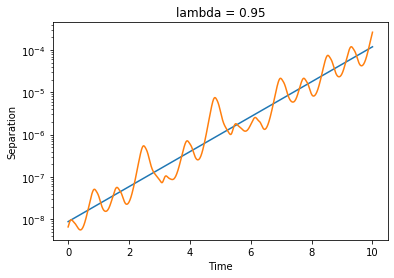

In [ ]:
# get initial conditions inside attractor
y0 = np.random.uniform(-15,15,size=3)
t_final = 10
domain = np.linspace(0,t_final,int(5e3))
y = odeint(lorenz,y0,domain)
#print(y.shape) #shape (len(domain),3) #so each row is 3 dimension place in time
#this is the initial condition from within the attractor
start = y[-1]
second = start + np.random.random((3,)) / int(1e8)
y1 = odeint(lorenz,start,domain)
y2 = odeint(lorenz,second,domain)
error = np.linalg.norm(y1 - y2,axis=1)
#https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html
result = linregress(domain,np.log(error))

plt.semilogy(domain,np.exp(result.slope * domain + result.intercept))
# plt.semilogy(domain,result.slope * domain + result.intercept)
plt.semilogy(domain,error)
# plt.semilogy(domain,np.exp(error))
plt.title(f'lambda = {np.round(result.slope,2)}')
plt.xlabel('Time')
plt.ylabel('Separation')
plt.show()